## Missing-Value Analysis

In [1]:
from pathlib import Path

import pandas as pd

from data.cleaning import (
    missingness_summary,
    row_missingness_summary,
)

PROJECT_ROOT = Path.cwd().parent

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "interim"
    / "train_merged.csv"
)

df = pd.read_csv(DATA_PATH)

print("Shape:", df.shape)

Shape: (590540, 434)


### Column-level missingness

In [2]:
missing_summary = missingness_summary(df)

missing_summary.head(30)

,missing_count,missing_rate
id_24,585793,0.991962
id_25,585408,0.991310
id_07,585385,0.991271
id_08,585385,0.991271
id_21,585381,0.991264
id_26,585377,0.991257
id_27,585371,0.991247
id_23,585371,0.991247
id_22,585371,0.991247
dist2,552913,0.936284


In [3]:
print(
    f"Columns with missing values: "
    f"{(missing_summary['missing_count'] > 0).sum()} / {df.shape[1]}"
)

print(
    f"Total missing cells: "
    f"{int(missing_summary['missing_count'].sum()):,}"
)

print(
    f"Overall missing-cell rate: "
    f"{missing_summary['missing_count'].sum() / df.size:.2%}"
)

Columns with missing values: 414 / 434
Total missing cells: 115,523,073
Overall missing-cell rate: 45.07%


### Row-level missingness

In [4]:
row_missingness = row_missingness_summary(df)

row_missingness.describe()

,missing_count,missing_rate
count,590540.000000,590540.000000
mean,195.622774,0.450744
std,49.035963,0.112986
min,24.000000,0.055300
25%,208.000000,0.479263
50%,211.000000,0.486175
75%,229.000000,0.527650
max,340.000000,0.783410


In [5]:
# Number of missing values in a row → Number of rows
row_missingness["missing_count"].value_counts().sort_index().head(20)

missing_count
24      1
26      3
27      7
28      1
29      6
30      9
31      5
32     15
33     23
34     66
35    102
36    133
37     97
38     78
39    113
40    118
41    107
42    109
43     82
44     56
Name: count, dtype: int64

### Missingness vs fraud

In [6]:
df["isFraud"].value_counts()

isFraud
0    569877
1     20663
Name: count, dtype: int64

In [7]:
missing_by_fraud = (
    df.drop(columns="isFraud")
    .isna()
    .assign(isFraud=df["isFraud"].to_numpy())
    .groupby("isFraud", observed=True)
    .mean()
    .mean(axis=1)
)

print(missing_by_fraud)

C:\Users\AYUSH PRASAD\AppData\Local\Temp\ipykernel_34148\1124757168.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  .assign(isFraud=df["isFraud"].to_numpy())


isFraud
0    0.454626
1    0.373436
dtype: float64


In [8]:
identity_columns = [
    column
    for column in df.columns
    if column.startswith("id_")
]

# checks whether at least one of the identity-related columns has a value for each row
identity_available = (
    df[identity_columns]
    .notna()
    .any(axis=1)
)

In [9]:
identity_fraud_rate = (
    df.assign(identity_available=identity_available)
    .groupby("identity_available")["isFraud"]
    .agg(
        transactions="size",
        fraud_count="sum",
        fraud_rate="mean",
    )
)

identity_fraud_rate["fraud_rate"] *= 100

identity_fraud_rate

C:\Users\AYUSH PRASAD\AppData\Local\Temp\ipykernel_34148\1852564242.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df.assign(identity_available=identity_available)


,transactions,fraud_count,fraud_rate
identity_available,,,
False,446307,9345,2.093850
True,144233,11318,7.847025


### Missingness by time period

In [10]:
time_quartile = pd.qcut(
    df["TransactionDT"],
    q=4,
    labels=[
        "Q1_Earliest",
        "Q2",
        "Q3",
        "Q4_Latest",
    ],
)

In [11]:
missing_over_time = (
    df.isna()
    .mean(axis=1)
    .groupby(time_quartile, observed=True)
    .mean()
    .rename("overall_missing_rate")
)

missing_over_time

TransactionDT
Q1_Earliest    0.422406
Q2             0.466560
Q3             0.459048
Q4_Latest      0.454960
Name: overall_missing_rate, dtype: float64

In [12]:
fraud_over_time = (
    df.groupby(time_quartile, observed=True)["isFraud"]
    .mean()
    .mul(100)
)

fraud_over_time

TransactionDT
Q1_Earliest    2.633522
Q2             4.068141
Q3             3.839875
Q4_Latest      3.454465
Name: isFraud, dtype: float64

### Missingness by feature group

The IEEE-CIS dataset has recognizable feature families such as:

C*
D*
V*
M*
id_*
card*

In [13]:
def feature_group(column: str) -> str:
    if column.startswith("id_"):
        return "identity"

    if column.startswith("card"):
        return "card"

    if column.startswith("addr"):
        return "address"

    if column.startswith("email"):
        return "email"

    if column.startswith("C"):
        return "C_features"

    if column.startswith("D"):
        return "D_features"

    if column.startswith("V"):
        return "V_features"

    if column.startswith("M"):
        return "M_features"

    return "other"

In [14]:
feature_groups = pd.Series(
    {column: feature_group(column) for column in df.columns},
    name="feature_group",
)

missing_by_group = (
    pd.DataFrame(
        {
            "feature_group": feature_groups,
            "missing_rate": df.isna().mean(),
        }
    )
    .groupby("feature_group")["missing_rate"]
    .agg(
        feature_count="size",
        mean_missing_rate="mean",
        median_missing_rate="median",
        max_missing_rate="max",
    )
    .sort_values(
        by="mean_missing_rate",
        ascending=False,
    )
)

missing_by_group

,feature_count,mean_missing_rate,median_missing_rate,max_missing_rate
feature_group,,,,
identity,38,0.848233,0.824428,0.991962
D_features,17,0.604900,0.761557,0.934099
M_features,9,0.499233,0.476588,0.593494
V_features,339,0.430385,0.472935,0.861237
other,9,0.273364,0.000000,0.936284
address,2,0.111264,0.111264,0.111264
card,6,0.005053,0.002665,0.015127
C_features,14,0.000000,0.000000,0.000000


### Investigating extremely sparse features

In [15]:
very_sparse = missing_summary[
    missing_summary["missing_rate"] >= 0.95
]

print(
    f"Features with >=95% missingness: "
    f"{len(very_sparse)}"
)

very_sparse

Features with >=95% missingness: 9


,missing_count,missing_rate
id_24,585793,0.991962
id_25,585408,0.991310
id_07,585385,0.991271
id_08,585385,0.991271
id_21,585381,0.991264
id_26,585377,0.991257
id_27,585371,0.991247
id_23,585371,0.991247
id_22,585371,0.991247


### For each feature - comparing missingness rate b/w Fraud & Legit Transactions

In [16]:
missing_by_class = (
    df.groupby("isFraud")
    .apply(lambda x: x.isna().mean(), include_groups=False)
    .T
    .rename(
        columns={
            0: "legitimate_missing_rate",
            1: "fraud_missing_rate"
        }
    )
)

missing_by_class["absolute_diff"] = (
    missing_by_class["fraud_missing_rate"] - missing_by_class["legitimate_missing_rate"]
).abs()

missing_by_class.sort_values("absolute_diff", ascending=False).head(20)

isFraud,legitimate_missing_rate,fraud_missing_rate,absolute_diff
R_emaildomain,0.778787,0.456662,0.322126
id_02,0.772495,0.456904,0.315591
id_36,0.772296,0.456904,0.315393
id_37,0.772296,0.456904,0.315393
id_35,0.772296,0.456904,0.315393
id_38,0.772296,0.456904,0.315393
id_15,0.772296,0.456904,0.315393
id_11,0.772302,0.457097,0.315205
id_29,0.772302,0.457097,0.315205
id_28,0.772302,0.457097,0.315205


## Duplicates Analysis

### Exact Duplicates

In [17]:
from data.cleaning import (
    duplicate_combination_summary,
    duplicate_transaction_id_count,
    exact_duplicate_count,
)

In [18]:
print(
    "Exact duplicate rows:",
    exact_duplicate_count(df),
)

print(
    "Duplicate TransactionID:",
    duplicate_transaction_id_count(df),
)

Exact duplicate rows: 0
Duplicate TransactionID: 0


### Duplicate-combination Analysis

In [19]:
duplicate_keys = {
    "card1": [
        "card1",
    ],
    "card1_addr1": [
        "card1",
        "addr1",
    ],
    "card1_email": [
        "card1",
        "P_emaildomain",
    ],
    "device_product": [
        "DeviceType",
        "DeviceInfo",
        "ProductCD",
    ],
}

In [20]:
duplicate_results = []

for name, columns in duplicate_keys.items():
    result = duplicate_combination_summary(
        df,
        columns,
    )

    duplicate_results.append(
        {
            "key": name,
            **result,
        }
    )

duplicate_results_df = pd.DataFrame(
    duplicate_results
)

duplicate_results_df

,key,columns,duplicated_rows,duplicated_row_rate,duplicated_groups,largest_group_size
0,card1,[card1],587096,0.994168,10109,14932
1,card1_addr1,"[card1, addr1]",574788,0.973326,24222,9928
2,card1_email,"[card1, P_emaildomain]",572869,0.970077,25810,7041
3,device_product,"[DeviceType, DeviceInfo, ProductCD]",589677,0.998539,1809,439670


#### card1 + addr1

In [21]:
card_addr_analysis = (
    df.groupby(
        ["card1", "addr1"],
        dropna=False,
    )
    .agg(
        transaction_count=("TransactionID", "size"),
        fraud_count=("isFraud", "sum"),
        fraud_rate=("isFraud", "mean"),
    )
    .reset_index()
)

In [22]:
card_addr_duplicates = card_addr_analysis[
    card_addr_analysis["transaction_count"] > 1
].copy()

card_addr_duplicates.sort_values(
    "transaction_count",
    ascending=False,
).head(20)

,card1,addr1,transaction_count,fraud_count,fraud_rate
34190,15885,NaN,9928,435,0.043815
37160,17188,299.0,5885,140,0.023789
27146,12695,325.0,5774,180,0.031174
19578,9500,204.0,4665,126,0.027010
4803,3154,NaN,4408,274,0.062160
19907,9633,NaN,3967,719,0.181245
27447,12839,264.0,3547,37,0.010431
34779,16132,299.0,3537,51,0.014419
33420,15497,299.0,3426,37,0.010800
19588,9500,272.0,2725,63,0.023119


In [23]:
# card_addr_groups with mixed fraud and legitimate transactions

mixed_card_addr_groups = card_addr_duplicates[
    (
        card_addr_duplicates["fraud_count"] > 0
    )
    &
    (
        card_addr_duplicates["fraud_count"]
        <
        card_addr_duplicates["transaction_count"]
    )
]

print(
    "Repeated card1+addr1 groups:",
    len(card_addr_duplicates),
)

print(
    "Repeated groups containing both fraud and legitimate transactions:",
    len(mixed_card_addr_groups),
)

Repeated card1+addr1 groups: 24222
Repeated groups containing both fraud and legitimate transactions: 2666


#### card1 + P_emaildomain

In [24]:
card_email_analysis = (
    df.groupby(
        ["card1", "P_emaildomain"],
        dropna=False,
    )
    .agg(
        transaction_count=("TransactionID", "size"),
        fraud_count=("isFraud", "sum"),
        fraud_rate=("isFraud", "mean"),
    )
    .reset_index()
)

In [25]:
card_email_duplicates = card_email_analysis[
    card_email_analysis["transaction_count"] > 1
]

card_email_duplicates.sort_values(
    "transaction_count",
    ascending=False,
).head(20)

,card1,P_emaildomain,transaction_count,fraud_count,fraud_rate
17247,7919,gmail.com,7041,54,0.007669
21291,9500,gmail.com,5605,184,0.032828
17266,7919,NaN,4465,45,0.010078
37190,15885,hotmail.com,4196,84,0.020019
40473,17188,gmail.com,4034,66,0.016361
37188,15885,gmail.com,3988,284,0.071214
35111,15066,gmail.com,3110,134,0.043087
21313,9500,yahoo.com,3058,196,0.064094
28838,12544,gmail.com,2945,62,0.021053
4540,2803,gmail.com,2877,22,0.007647


#### device + product

In [26]:
device_product_analysis = (
    df.groupby(
        [
            "DeviceType",
            "DeviceInfo",
            "ProductCD",
        ],
        dropna=False,
    )
    .agg(
        transaction_count=("TransactionID", "size"),
        fraud_count=("isFraud", "sum"),
        fraud_rate=("isFraud", "mean"),
    )
    .reset_index()
)

In [27]:
device_product_duplicates = (
    device_product_analysis[
        device_product_analysis["transaction_count"] > 1
    ]
    .sort_values(
        "transaction_count",
        ascending=False,
    )
)

device_product_duplicates.head(20)

,DeviceType,DeviceInfo,ProductCD,transaction_count,fraud_count,fraud_rate
2671,NaN,NaN,W,439670,8969,0.020399
183,desktop,Windows,C,17941,1960,0.109247
185,desktop,Windows,R,13429,286,0.021297
184,desktop,Windows,H,10288,619,0.060167
300,desktop,NaN,C,10190,1352,0.132679
2608,mobile,iOS Device,H,9832,505,0.051363
2659,mobile,NaN,C,9232,993,0.107561
2609,mobile,iOS Device,R,9154,673,0.073520
2667,NaN,NaN,C,7504,414,0.055171
186,desktop,Windows,S,6062,256,0.042230


## Outlier Analysis

### TransactionAmt

In [28]:
from data.cleaning import numeric_outlier_summary

In [29]:
transaction_amt_outliers = numeric_outlier_summary(
    df,
    "TransactionAmt",
)

transaction_amt_outliers

{'q1': 43.321,
 'q3': 125.0,
 'iqr': 81.679,
 'lower_bound': -79.1975,
 'upper_bound': 247.51850000000002,
 'outlier_count': 66482,
 'outlier_rate': 0.11257831814949029}

In [30]:
df["TransactionAmt"].describe()

count    590540.000000
mean        135.027176
std         239.162522
min           0.251000
25%          43.321000
50%          68.769000
75%         125.000000
max       31937.391000
Name: TransactionAmt, dtype: float64

#### Checking Skewness

In [31]:
df["TransactionAmt"].skew()
# This means TransactionAmt is highly right-skewed

np.float64(14.374489573829827)

In [32]:
# Trying to understand the upper tail
df["TransactionAmt"].quantile(
    [0.50, 0.75, 0.90, 0.95, 0.99, 0.995, 0.999, 1.00]
)

0.500       68.76900
0.750      125.00000
0.900      275.29300
0.950      445.00000
0.990     1104.00000
0.995     1656.11000
0.999     2769.80732
1.000    31937.39100
Name: TransactionAmt, dtype: float64

#### Checking for clearly invalid values

In [33]:
print("Negative amounts:", (df["TransactionAmt"] < 0).sum())
print("Zero amounts:", (df["TransactionAmt"] == 0).sum())
print("Missing amounts:", df["TransactionAmt"].isna().sum())

Negative amounts: 0
Zero amounts: 0
Missing amounts: 0


#### Grouping By fraud class and checking TransactionAmt stats

In [34]:
transaction_amt_by_class = (
    df.groupby("isFraud")["TransactionAmt"]
    .describe(
        percentiles=[
            0.50,
            0.75,
            0.90,
            0.95,
            0.99,
            0.999,
        ]
    )
)

transaction_amt_by_class

,count,mean,std,min,50%,75%,90%,95%,99%,99.9%,max
isFraud,,,,,,,,,,,
0,569877.0,134.511665,239.395078,0.251,68.5,120.0,267.112,435.0,1104.0,2775.38068,31937.391
1,20663.0,149.244779,232.212163,0.292,75.0,161.0,335.000,500.0,994.0,2680.33462,5191.000


#### Checking fraud stats for normal transactionAmts vs outlier transactionAmts

In [35]:
outlier_lower = transaction_amt_outliers["lower_bound"]
outlier_upper = transaction_amt_outliers["upper_bound"]

transaction_amt_is_outlier = (
    (df["TransactionAmt"] < outlier_lower)
    | (df["TransactionAmt"] > outlier_upper)
)

In [36]:
outlier_class_summary = (
    df.assign(
        transaction_amt_outlier=transaction_amt_is_outlier
    )
    .groupby("transaction_amt_outlier")["isFraud"]
    .agg(
        transactions="size",
        fraud_count="sum",
        fraud_rate="mean",
    )
)

outlier_class_summary["fraud_rate"] *= 100

outlier_class_summary

C:\Users\AYUSH PRASAD\AppData\Local\Temp\ipykernel_34148\674076334.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df.assign(


,transactions,fraud_count,fraud_rate
transaction_amt_outlier,,,
False,524058,17291,3.299444
True,66482,3372,5.072050


#### Inspecting Extreme Transactions

In [37]:
df[
    [
        "TransactionID",
        "TransactionDT",
        "TransactionAmt",
        "isFraud",
    ]
].sort_values(
    "TransactionAmt",
    ascending=False,
).head(20)

,TransactionID,TransactionDT,TransactionAmt,isFraud
274339,3261339,6652391,31937.391,0
274336,3261336,6652360,31937.391,0
296021,3283021,7320188,6450.970,0
248413,3235413,5926506,6085.230,0
384603,3371603,9648912,5543.230,0
275535,3262535,6706356,5420.000,0
275529,3262529,6706260,5420.000,0
584767,3571767,15632496,5366.820,0
315172,3302172,7850500,5279.950,0
462514,3449514,11901553,5279.950,0


#### Comparing raw and log-scaled amounts

In [38]:
import numpy as np

transaction_amt_log1p = np.log1p(
    df["TransactionAmt"]
)

In [39]:
print(
    "Raw skewness:",
    df["TransactionAmt"].skew(),
)

print(
    "log1p skewness:",
    transaction_amt_log1p.skew(), # type: ignore
)

Raw skewness: 14.374489573829827
log1p skewness: 0.4882909971465319


In [40]:
transaction_amt_log1p.describe() # type: ignore

count    590540.000000
mean          4.382960
std           0.937183
min           0.223943
25%           3.791459
50%           4.245190
75%           4.836282
max          10.371564
Name: TransactionAmt, dtype: float64

#### Comparing extreme values before and after log transformation

In [41]:
comparison = pd.DataFrame(
    {
        "raw": df["TransactionAmt"],
        "log1p": transaction_amt_log1p,
    }
)

comparison.quantile(
    [
        0.50,
        0.75,
        0.90,
        0.95,
        0.99,
        0.999,
        1.00,
    ]
)

,raw,log1p
0.500,68.76900,4.245190
0.750,125.00000,4.836282
0.900,275.29300,5.621462
0.950,445.00000,6.100319
0.990,1104.00000,7.007601
0.999,2769.80732,7.926894
1.000,31937.39100,10.371564


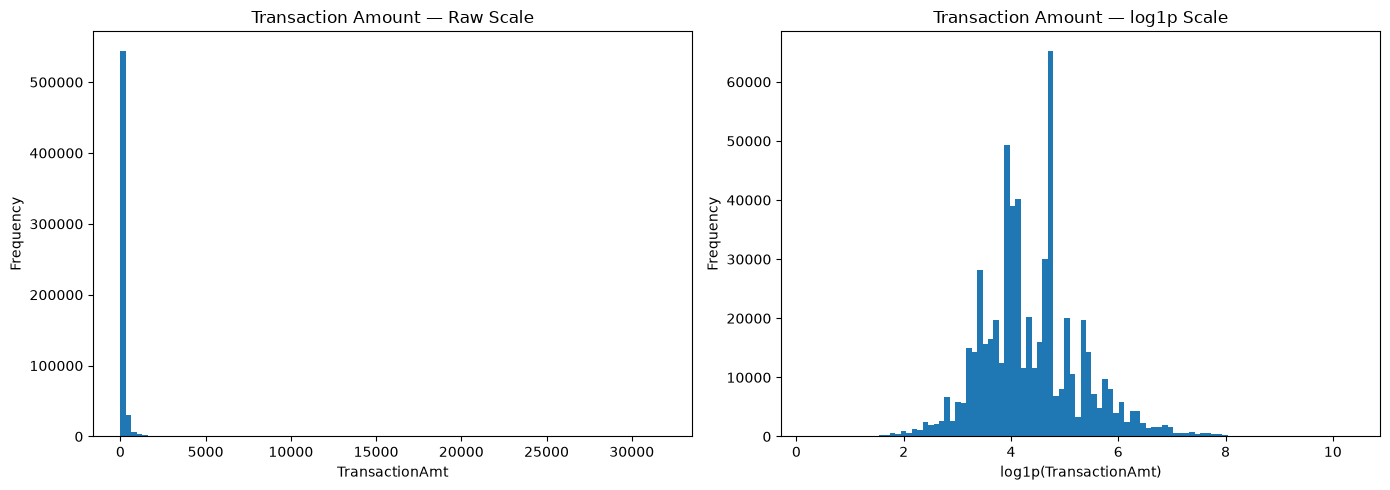

In [42]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5),
)

axes[0].hist(
    df["TransactionAmt"].dropna(),
    bins=100,
)

axes[0].set_title("Transaction Amount — Raw Scale")
axes[0].set_xlabel("TransactionAmt")
axes[0].set_ylabel("Frequency")

axes[1].hist(
    transaction_amt_log1p.dropna(), # type: ignore
    bins=100,
)

axes[1].set_title("Transaction Amount — log1p Scale")
axes[1].set_xlabel("log1p(TransactionAmt)")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

### Other Numeric Columns

In [43]:
numeric_columns = df.select_dtypes(
    include=np.number
).columns.tolist()

numeric_columns.remove("isFraud")
numeric_columns

['TransactionID',
 'TransactionDT',
 'TransactionAmt',
 'card1',
 'card2',
 'card3',
 'card5',
 'addr1',
 'addr2',
 'dist1',
 'dist2',
 'C1',
 'C2',
 'C3',
 'C4',
 'C5',
 'C6',
 'C7',
 'C8',
 'C9',
 'C10',
 'C11',
 'C12',
 'C13',
 'C14',
 'D1',
 'D2',
 'D3',
 'D4',
 'D5',
 'D6',
 'D7',
 'D8',
 'D9',
 'D10',
 'D11',
 'D12',
 'D13',
 'D14',
 'D15',
 'V1',
 'V2',
 'V3',
 'V4',
 'V5',
 'V6',
 'V7',
 'V8',
 'V9',
 'V10',
 'V11',
 'V12',
 'V13',
 'V14',
 'V15',
 'V16',
 'V17',
 'V18',
 'V19',
 'V20',
 'V21',
 'V22',
 'V23',
 'V24',
 'V25',
 'V26',
 'V27',
 'V28',
 'V29',
 'V30',
 'V31',
 'V32',
 'V33',
 'V34',
 'V35',
 'V36',
 'V37',
 'V38',
 'V39',
 'V40',
 'V41',
 'V42',
 'V43',
 'V44',
 'V45',
 'V46',
 'V47',
 'V48',
 'V49',
 'V50',
 'V51',
 'V52',
 'V53',
 'V54',
 'V55',
 'V56',
 'V57',
 'V58',
 'V59',
 'V60',
 'V61',
 'V62',
 'V63',
 'V64',
 'V65',
 'V66',
 'V67',
 'V68',
 'V69',
 'V70',
 'V71',
 'V72',
 'V73',
 'V74',
 'V75',
 'V76',
 'V77',
 'V78',
 'V79',
 'V80',
 'V81',
 'V82',
 'V8

In [44]:
outlier_screening = []

for column in numeric_columns:
    try:
        result = numeric_outlier_summary(
            df,
            column,
        )

        outlier_screening.append(
            {
                "feature": column,
                "outlier_count": result["outlier_count"],
                "outlier_rate": result["outlier_rate"],
                "lower_bound": result["lower_bound"],
                "upper_bound": result["upper_bound"],
            }
        )
    except (TypeError, ValueError):
        continue

outlier_screening_df = pd.DataFrame(
    outlier_screening
).sort_values(
    "outlier_rate",
    ascending=False,
)

outlier_screening_df.head(20)

,feature,outlier_count,outlier_rate,lower_bound,upper_bound
261,V222,61082,0.431931,1.0,1.0
260,V221,58701,0.415094,1.0,1.0
390,id_13,42014,0.329987,44.5,56.5
399,id_25,1604,0.312549,246.0,446.0
298,V259,43943,0.310736,1.0,1.0
210,V171,43001,0.307548,1.0,1.0
209,V170,38310,0.273997,1.0,1.0
284,V245,38421,0.271688,1.0,1.0
302,V263,32145,0.246454,0.0,0.0
256,V217,32145,0.246454,0.0,0.0


## Analyzing Incosistent Data

#### Empty strings and whitespace

In [45]:
string_cols = df.select_dtypes(include=["object", "string"]).columns

empty_string_counts = {}

for col in string_cols:
    count = df[col].astype("string").str.strip().eq("").sum()

    if count > 0:
        empty_string_counts[col] = count

empty_string_counts

{}

#### Checking for Casing inconsistencies

In [46]:
casing_issues = {}

for col in string_cols:
    values = df[col].dropna().astype("string").str.strip()

    normalized_groups = values.groupby(values.str.lower()).nunique()

    issues = normalized_groups[normalized_groups > 1]

    if not issues.empty:
        casing_issues[col] = issues


casing_issues

{'DeviceInfo': DeviceInfo
 alcatel    2
 dash       2
 ilium      2
 mi         2
 moto       2
 stellar    2
 vivo       2
 Name: DeviceInfo, dtype: int64}

#### Checking for sentinel values

In [47]:
sentinel_candidates = [
    "unknown",
    "Unknown",
    "UNKNOWN",
    "N/A",
    "n/a",
    "NA",
    "na",
    "None",
    "none",
    "NULL",
    "null",
    "-1",
    "0",
]

sentinel_counts = {}

for col in string_cols:
    counts = (
        df[col]
        .astype("string")
        .value_counts(dropna=False)
    )

    matches = counts[
        counts.index.astype("string").isin(sentinel_candidates)
    ]

    if not matches.empty:
        sentinel_counts[col] = matches

sentinel_counts

{'id_15': id_15
 Unknown    11645
 Name: count, dtype: Int64}

#### Numerical consistency check

In [48]:
numeric_cols = df.select_dtypes(include="number").columns

negative_counts = {}
zero_counts = {}

for col in numeric_cols:
    negative = (df[col] < 0).sum()
    zero = (df[col] == 0).sum()

    if negative > 0:
        negative_counts[col] = negative

    if zero > 0:
        zero_counts[col] = zero

print("Negative values:")
print(negative_counts)

print("\nZero values:")
print(zero_counts)

Negative values:
{'D4': np.int64(15), 'D6': np.int64(3), 'D11': np.int64(7), 'D12': np.int64(2), 'D14': np.int64(3), 'D15': np.int64(15), 'id_01': np.int64(124678), 'id_03': np.int64(187), 'id_04': np.int64(585), 'id_05': np.int64(6097), 'id_06': np.int64(45540), 'id_07': np.int64(347), 'id_08': np.int64(4894), 'id_09': np.int64(463), 'id_10': np.int64(2047), 'id_14': np.int64(79113)}

Zero values:
{'isFraud': np.int64(569877), 'dist1': np.int64(19824), 'dist2': np.int64(3519), 'C1': np.int64(494), 'C2': np.int64(443), 'C3': np.int64(588111), 'C4': np.int64(451883), 'C5': np.int64(372435), 'C6': np.int64(49066), 'C7': np.int64(523142), 'C8': np.int64(447667), 'C9': np.int64(183795), 'C10': np.int64(453442), 'C11': np.int64(1864), 'C12': np.int64(489199), 'C13': np.int64(35460), 'C14': np.int64(35947), 'D1': np.int64(280130), 'D2': np.int64(15124), 'D3': np.int64(73094), 'D4': np.int64(166571), 'D5': np.int64(65377), 'D6': np.int64(45782), 'D7': np.int64(21135), 'D8': np.int64(835), 'D9

In [49]:
negative_summary = (
    df[list(negative_counts)]
    .agg(["min", "max", "count"])
    .T
)

negative_summary["negative_count"] = pd.Series(negative_counts)

negative_summary.sort_values("negative_count", ascending=False)

,min,max,count,negative_count
id_01,-100.0,0.0,144233.0,124678
id_14,-660.0,720.0,80044.0,79113
id_06,-100.0,0.0,136865.0,45540
id_05,-72.0,52.0,136865.0,6097
id_08,-100.0,0.0,5155.0,4894
id_10,-100.0,0.0,74926.0,2047
id_04,-28.0,0.0,66324.0,585
id_09,-36.0,25.0,74926.0,463
id_07,-46.0,61.0,5155.0,347
id_03,-13.0,10.0,66324.0,187


In [50]:
inf_counts = np.isinf(df[numeric_cols]).sum()

inf_counts = inf_counts[inf_counts > 0]

print("Infinite values:")
print(inf_counts)

Infinite values:
Series([], dtype: int64)
